# Titanic Survival Prediction — Logistic Regression & Regularization

This notebook follows a leakage-safe machine-learning workflow:

1. Load and inspect the Titanic training data.
2. Explore missing values and distributions.
3. Split the data into training and validation sets.
4. Impute missing values, scale numeric features, and encode categorical features **inside a Pipeline**.
5. Train and evaluate Logistic Regression.
6. Compare L1 and L2 regularization across different values of `C`.
7. Optionally predict the Kaggle `test.csv` file and create `submission.csv`.

**Before running:** Put `train.csv` and (optionally) `test.csv` in the same folder as this notebook. If they are elsewhere, change `DATA_DIR` in the next cell.

The notebook does not assume a particular Windows username or file path.


## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load the dataset

In [2]:
# Keep train.csv and test.csv in the same folder as this notebook.
# Example for a custom Windows folder:
# DATA_DIR = Path(r"C:\Users\hp\Music\ml_classproject\practise_folder\regularization")

DATA_DIR = Path(".")
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {TRAIN_PATH.resolve()}. "
        "Place train.csv beside this notebook or update DATA_DIR."
    )

df_train = pd.read_csv(TRAIN_PATH)

print("Training data shape:", df_train.shape)
display(df_train.head())


Training data shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Inspect and clean the raw training data

In [3]:
print("Column information:")
df_train.info()

print("\\nMissing values:")
display(df_train.isnull().sum().sort_values(ascending=False))

print("\\nDuplicate rows:", df_train.duplicated().sum())

# Remove exact duplicate rows.
df_train = df_train.drop_duplicates().copy()

# The target must exist in the training data.
if "Survived" not in df_train.columns:
    raise ValueError("The training file must contain the 'Survived' target column.")

# Check target values.
display(df_train["Survived"].value_counts(dropna=False))


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
\nMissing values:


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

\nDuplicate rows: 0


Survived
0    549
1    342
Name: count, dtype: int64

## 4. Exploratory data analysis

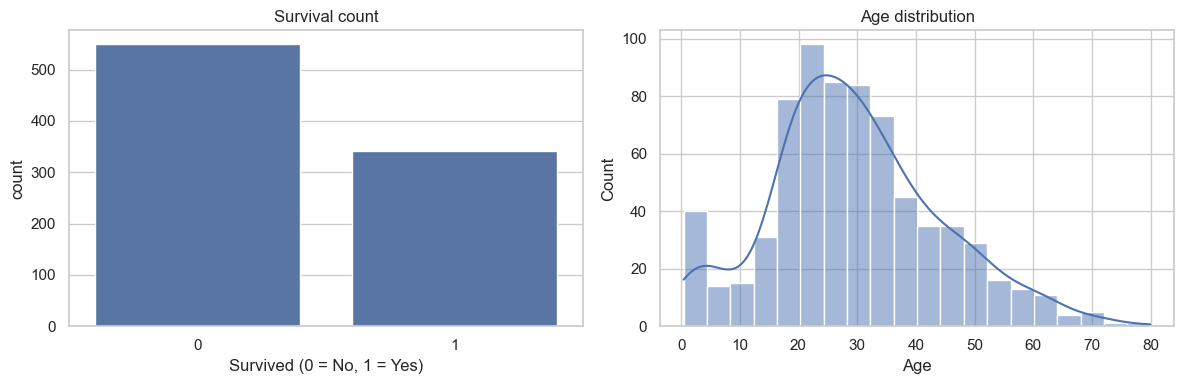

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_train, x="Survived", ax=axes[0])
axes[0].set_title("Survival count")
axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")

sns.histplot(data=df_train, x="Age", kde=True, ax=axes[1])
axes[1].set_title("Age distribution")

plt.tight_layout()
plt.show()


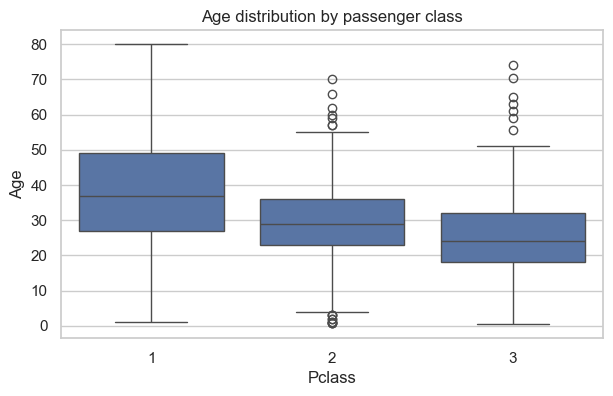

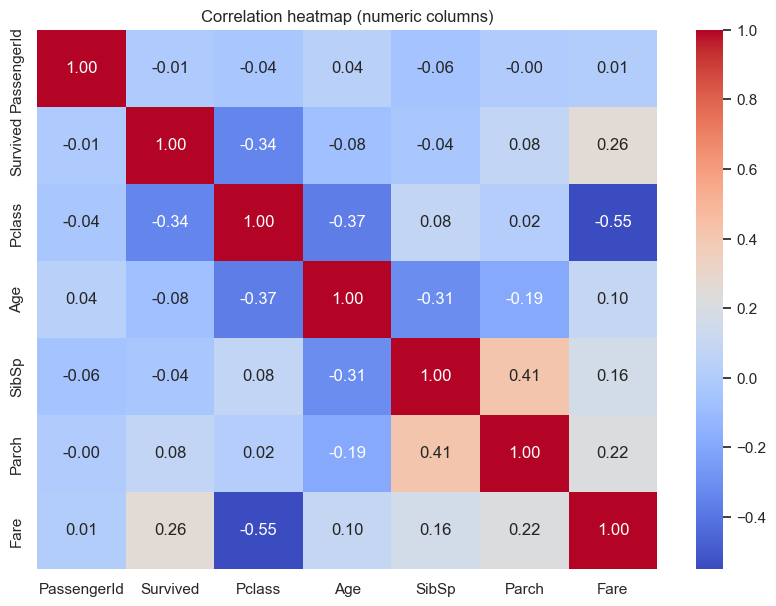

In [5]:
if {"Pclass", "Age"}.issubset(df_train.columns):
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df_train, x="Pclass", y="Age")
    plt.title("Age distribution by passenger class")
    plt.show()

numeric_for_corr = df_train.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap (numeric columns)")
plt.show()


## 5. Separate features and target

We exclude `PassengerId`, `Name`, `Ticket`, and `Cabin` from this baseline model:
- `PassengerId` is an identifier.
- `Name` and `Ticket` are text fields that need feature engineering to use effectively.
- `Cabin` has many missing values in the classic Titanic dataset.

We keep `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked` when present.


In [6]:
TARGET = "Survived"
DROP_COLUMNS = ["PassengerId", "Name", "Ticket", "Cabin"]

X = df_train.drop(columns=[TARGET] + DROP_COLUMNS, errors="ignore")
y = df_train[TARGET].astype(int)

if y.isna().any():
    raise ValueError("The target column contains missing values.")

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
print("\\nFeature data types:")
display(X.dtypes)


Features shape: (891, 7)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


\nFeature data types:


Pclass        int64
Sex             str
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked        str
dtype: object

## 6. Split before fitting preprocessing

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("Training survival rate:", round(y_train.mean(), 3))
print("Validation survival rate:", round(y_val.mean(), 3))


X_train: (712, 7)
X_val: (179, 7)
Training survival rate: 0.383
Validation survival rate: 0.385


## 7. Build a preprocessing and modeling pipeline

- Numeric columns: median imputation, then standard scaling.
- Categorical columns: most-frequent imputation, then one-hot encoding.
- Logistic Regression is fitted after preprocessing.

Because preprocessing is inside the Pipeline, imputation values, scaling statistics, and category encodings are learned from `X_train` only. This avoids leaking validation information into training.


In [8]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)
y_pred = logistic_model.predict(X_val)


## 8. Evaluate the baseline Logistic Regression

Training accuracy:   0.8076
Validation accuracy: 0.8045
\nClassification report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



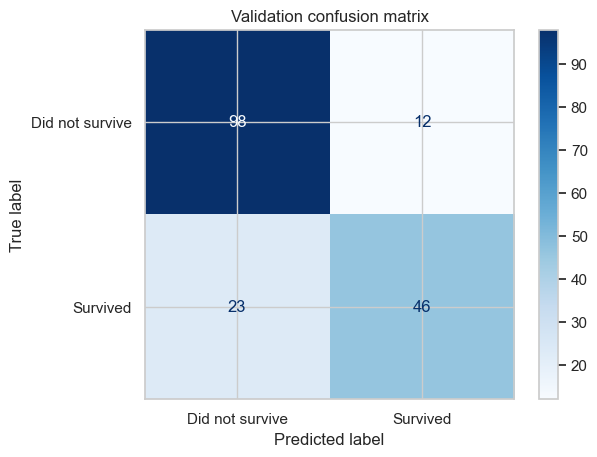

In [9]:
print(f"Training accuracy:   {logistic_model.score(X_train, y_train):.4f}")
print(f"Validation accuracy: {accuracy_score(y_val, y_pred):.4f}")

print("\\nClassification report:")
print(classification_report(y_val, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Validation confusion matrix")
plt.show()


## 9. Compare L1 and L2 regularization

`C` is the inverse of regularization strength:
- Smaller `C` → stronger regularization.
- Larger `C` → weaker regularization.

L1 can set some coefficients exactly to zero. L2 generally shrinks coefficients without making them exactly zero.

We compare validation accuracy for a range of `C` values. This is an experiment on the validation set; for a final unbiased performance estimate, use cross-validation or a separate untouched test split.


In [10]:
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]
results = []

for penalty, solver in [("l1", "liblinear"), ("l2", "lbfgs")]:
    for c_value in C_VALUES:
        model = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                penalty=penalty,
                C=c_value,
                solver=solver,
                max_iter=3000,
                random_state=RANDOM_STATE
            ))
        ])

        model.fit(X_train, y_train)
        train_accuracy = model.score(X_train, y_train)
        val_accuracy = model.score(X_val, y_val)

        results.append({
            "Penalty": penalty.upper(),
            "C": c_value,
            "Training accuracy": train_accuracy,
            "Validation accuracy": val_accuracy
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["Penalty", "C"]))


c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\hp\AppData\Local\Python\pythonc

,Penalty,C,Training accuracy,Validation accuracy
0,L1,0.001,0.616573,0.614525
1,L1,0.010,0.789326,0.776536
2,L1,0.100,0.801966,0.798883
3,L1,1.000,0.803371,0.804469
4,L1,10.000,0.806180,0.810056
5,L1,100.000,0.807584,0.810056
6,L2,0.001,0.632022,0.631285
7,L2,0.010,0.783708,0.782123
8,L2,0.100,0.806180,0.793296
9,L2,1.000,0.807584,0.804469


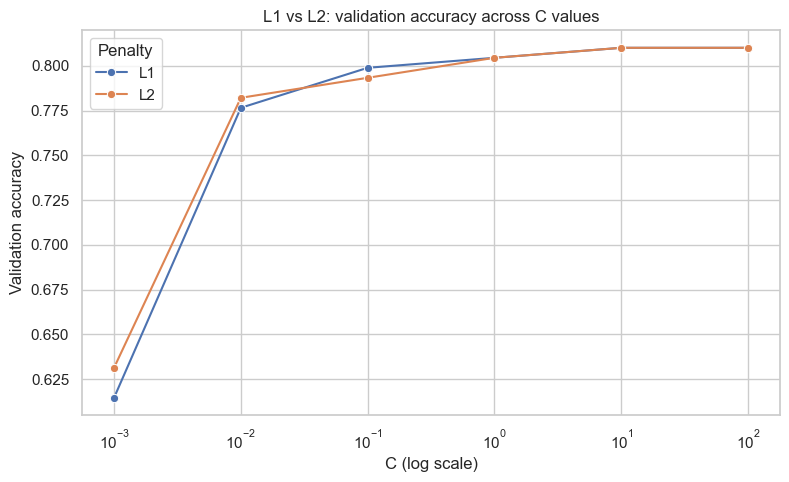

In [11]:
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=results_df,
    x="C",
    y="Validation accuracy",
    hue="Penalty",
    marker="o"
)
plt.xscale("log")
plt.title("L1 vs L2: validation accuracy across C values")
plt.xlabel("C (log scale)")
plt.ylabel("Validation accuracy")
plt.show()


## 10. Fit the selected model

Choose a penalty and `C` based on the comparison above. The defaults below use L2 with `C=1.0`. Change them if your experiment supports another choice.

In [12]:
BEST_PENALTY = "l2"   # "l1" or "l2"
BEST_C = 1.0

best_solver = "liblinear" if BEST_PENALTY == "l1" else "lbfgs"

best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        penalty=BEST_PENALTY,
        C=BEST_C,
        solver=best_solver,
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

best_model.fit(X_train, y_train)

best_predictions = best_model.predict(X_val)
print("Selected penalty:", BEST_PENALTY.upper())
print("Selected C:", BEST_C)
print("Validation accuracy:", round(accuracy_score(y_val, best_predictions), 4))


Selected penalty: L2
Selected C: 1.0
Validation accuracy: 0.8045


## 11. Inspect model coefficients

In [13]:
# Get feature names after one-hot encoding.
fitted_preprocessor = best_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = best_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
coef_df["Absolute coefficient"] = coef_df["Coefficient"].abs()

display(coef_df.sort_values("Absolute coefficient", ascending=False))


,Feature,Coefficient,Absolute coefficient
6,categorical__Sex_male,-1.320718,1.320718
5,categorical__Sex_female,1.299444,1.299444
0,numeric__Pclass,-0.921972,0.921972
1,numeric__Age,-0.502815,0.502815
9,categorical__Embarked_S,-0.358305,0.358305
8,categorical__Embarked_Q,0.304784,0.304784
2,numeric__SibSp,-0.260607,0.260607
4,numeric__Fare,0.100269,0.100269
3,numeric__Parch,-0.066424,0.066424
7,categorical__Embarked_C,0.032247,0.032247


## 12. Optional: predict Kaggle test.csv and create submission.csv

The Kaggle test file has no `Survived` column. We use the selected model to predict it. The model is fitted on the training portion used above; for a competition submission, it is better to refit on **all labeled training rows** after finalizing the approach.

This cell:
- loads `test.csv`,
- preserves `PassengerId` for the submission,
- applies the same fitted pipeline,
- writes `submission.csv` beside the notebook.


In [14]:
if TEST_PATH.exists():
    df_test = pd.read_csv(TEST_PATH)

    if "PassengerId" not in df_test.columns:
        raise ValueError("test.csv must contain PassengerId to create a Kaggle submission.")

    test_ids = df_test["PassengerId"].copy()

    X_test = df_test.drop(columns=DROP_COLUMNS, errors="ignore")

    # Refit on all labeled training rows for the final competition predictions.
    X_all = df_train.drop(columns=[TARGET] + DROP_COLUMNS, errors="ignore")
    y_all = df_train[TARGET].astype(int)

    final_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            penalty=BEST_PENALTY,
            C=BEST_C,
            solver=best_solver,
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ])

    final_model.fit(X_all, y_all)
    test_predictions = final_model.predict(X_test)

    submission = pd.DataFrame({
        "PassengerId": test_ids,
        "Survived": test_predictions.astype(int)
    })

    submission_path = DATA_DIR / "submission.csv"
    submission.to_csv(submission_path, index=False)

    print(f"Submission saved to: {submission_path.resolve()}")
    display(submission.head())
else:
    print("test.csv was not found. Skipping submission generation.")
    print("Place test.csv beside this notebook and run this cell again.")


Submission saved to: C:\Users\hp\Music\ml_classproject\practise_folder\logistic_regression\submission.csv


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## 13. Key takeaways

- `drop_duplicates()` must be reassigned or used with `inplace=True`.
- `pd.get_dummies()` returns a new DataFrame; it does not modify the original unless reassigned.
- Split before fitting preprocessing steps.
- Use `fit_transform()` on training data and `transform()` on validation/test data. A Pipeline handles this automatically.
- Scale numeric features for Logistic Regression.
- `C` is inverse regularization strength.
- Do not judge a model using accuracy alone; also inspect precision, recall, F1-score, and the confusion matrix.
